<a href="https://colab.research.google.com/github/yashnayak25-debug/Dsc212Assignment/blob/main/KarateClub.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recursive Spectral Partitioning on the Zachary's Karate Club Graph

This project implements a **Recursive Spectral Graph Partitioning** algorithm from scratch, complete with iterative modularity optimization (Kernighan-Lin style refinement passes) and tracks how structural node metrics (such as Centrality and Clustering Coefficients) evolve as communities split.

---

## Mathematical Background

### 1. The Modularity Matrix ($B$)
For an unweighted graph, the modularity matrix $B$ is defined as:
$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$
where:
* $A$ is the adjacency matrix.
* $k_i, k_j$ are the degrees of nodes $i$ and $j$.
* $m$ is the total number of edges in the graph.

### 2. Spectral Bisection
We look for a membership vector $s \in \{-1, 1\}^n$ that maximizes the modularity parameter $Q = \frac{1}{4m} s^T B s$. By relaxing the constraint to $s^T s = n$, the optimal $s$ aligns with the eigenvector associated with the largest positive eigenvalue of the modularity matrix $B$.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from typing import List, Dict, Tuple, Optional

class RecursiveSpectralPartitioner:
    """
    A professional class to handle recursive spectral partitioning of a graph
    using modularity matrix eigenvectors and tracking structural metric evolution.
    """
    def __init__(self, G: nx.Graph, seed: int = 42):
        self.G = G.copy()
        self.nodes = list(self.G.nodes())
        self.n = self.G.number_of_nodes()
        self.m = self.G.number_of_edges()
        self.seed = seed

        # Precompute Adjacency and Modularity Matrix
        self.A = nx.to_numpy_array(self.G, nodelist=self.nodes, weight=None)
        self.degrees = np.array([self.G.degree(i) for i in self.nodes])
        self.B = self.A - np.outer(self.degrees, self.degrees) / (2 * self.m)

        # Fixed layout for consistent visualization
        self.pos = nx.spring_layout(self.G, seed=self.seed)

        # Execution history
        self.snapshots: List[Tuple[List[List[int]], str]] = []
        self.split_log: List[Tuple[List[int], List[int], List[int], float, float]] = []
        self.metric_history: List[Dict[str, Dict[int, float]]] = []
        self.communities: List[List[int]] = []

    def compute_node_metrics(self, graph: nx.Graph) -> Dict[str, Dict[int, float]]:
        """Computes structural node metrics for a given graph state."""
        return {
            "Degree centrality": nx.degree_centrality(graph),
            "Betweenness centrality": nx.betweenness_centrality(graph),
            "Closeness centrality": nx.closeness_centrality(graph),
            "Clustering coefficient": nx.clustering(graph)
        }

    def _spectral_partition(self, C: List[int], tol: float = 1e-10, max_passes: int = 100) -> Optional[Tuple[List[int], List[int], float, float]]:
        """Helper to perform a single spectral partition split on community subset C."""
        if len(C) < 2:
            return None

        idx = np.array(C, dtype=int)
        B_C = self.B[np.ix_(idx, idx)].copy()
        B_gamma = B_C - np.diag(B_C.sum(axis=1))

        eigenvalues, eigenvectors = np.linalg.eigh(B_gamma)
        j = np.argmax(eigenvalues)

        if eigenvalues[j] <= tol:
            return None

        signs = np.where(eigenvectors[:, j] >= 0, 1, -1)

        def gain(s: np.ndarray) -> float:
            return float(s @ B_gamma @ s) / (4 * self.m)

        current_gain = gain(signs)

        # Greedily flip signs when modularity gain improves (sign refinement)
        for _ in range(max_passes):
            best_gain = current_gain
            best_i = None

            for i in range(len(signs)):
                trial = signs.copy()
                trial[i] *= -1
                trial_gain = gain(trial)

                if trial_gain > best_gain + tol:
                    best_gain = trial_gain
                    best_i = i

            if best_i is None:
                break

            signs[best_i] *= -1
            current_gain = best_gain

        left = [C[i] for i in range(len(C)) if signs[i] == 1]
        right = [C[i] for i in range(len(C)) if signs[i] == -1]

        if not left or not right or current_gain <= tol:
            return None

        return left, right, current_gain, eigenvalues[j]

    def run(self):
        """Runs the recursive bisection pipeline."""
        self.communities = [self.nodes.copy()]
        queue = [self.nodes.copy()]

        self.snapshots = [([c.copy() for c in self.communities], "Iteration 0: Full graph")]
        self.split_log = []

        while queue:
            candidate = queue.pop(0)
            result = self._spectral_partition(candidate)

            if result is None:
                continue

            left, right, gain, leading_eigenvalue = result
            self.split_log.append((candidate.copy(), left.copy(), right.copy(), gain, leading_eigenvalue))

            self.communities.remove(candidate)
            self.communities.extend([left, right])
            queue.extend([left, right])

            self.snapshots.append((
                [c.copy() for c in self.communities],
                f"Iteration {len(self.split_log)}: {len(self.communities)} communities"
            ))

        # Process metric history tracking
        self.metric_history = []
        for partition, _ in self.snapshots:
            labels = self._get_labels(partition)
            H = self.G.copy()
            H.remove_edges_from([
                (u, v) for u, v in self.G.edges() if labels[u] != labels[v]
            ])
            self.metric_history.append(self.compute_node_metrics(H))

    def _get_labels(self, partition: List[List[int]]) -> Dict[int, int]:
        labels = {}
        for cid, community in enumerate(partition):
            for node in community:
                labels[node] = cid
        return labels

    def plot_visualizations(self):
        """Plots community states at each split iteration."""
        for partition, title in self.snapshots:
            labels = self._get_labels(partition)
            plt.figure(figsize=(7, 5))
            nx.draw_networkx(
                self.G,
                self.pos,
                node_color=[labels[node] for node in self.nodes],
                cmap=plt.cm.tab10,
                node_size=400,
                font_size=8,
                edge_color="gray",
                with_labels=True
            )
            plt.title(title)
            plt.axis("off")
            plt.tight_layout()
            plt.show()

    def plot_metrics(self):
        """Plots the metric tracking evolution curves."""
        iterations = range(len(self.metric_history))
        for metric in list(self.metric_history[0].keys()):
            plt.figure(figsize=(10, 5))
            for node in self.nodes:
                values = [history[metric][node] for history in self.metric_history]
                plt.plot(iterations, values, marker="o", markersize=3, linewidth=1, alpha=0.6)
            plt.xlabel("Partition iteration")
            plt.ylabel(metric)
            plt.title(f"{metric} evolution across recursive partitioning")
            plt.xticks(list(iterations))
            plt.grid(alpha=0.25)
            plt.tight_layout()
            plt.show()

    def print_summary(self):
        """Prints execution summary metrics."""
        print(f"Dataset: Zachary's Karate Club ({self.n} nodes, {self.m} edges)")
        print(f"Total Accepted Splits: {len(self.split_log)}")
        print(f"Final Detected Communities: {len(self.communities)}")
        print("\n--- Split History ---")
        for idx, (parent, left, right, gain, val) in enumerate(self.split_log, start=1):
            print(f"Split #{idx}: Parent size {len(parent)} -> Left {len(left)} | Right {len(right)} (Modularity Gain: {gain:.4f})")

Dataset: Zachary's Karate Club (34 nodes, 78 edges)
Total Accepted Splits: 3
Final Detected Communities: 4

--- Split History ---
Split #1: Parent size 34 -> Left 17 | Right 17 (Modularity Gain: 0.3718)
Split #2: Parent size 17 -> Left 5 | Right 12 (Modularity Gain: 0.0302)
Split #3: Parent size 17 -> Left 11 | Right 6 (Modularity Gain: 0.0168)


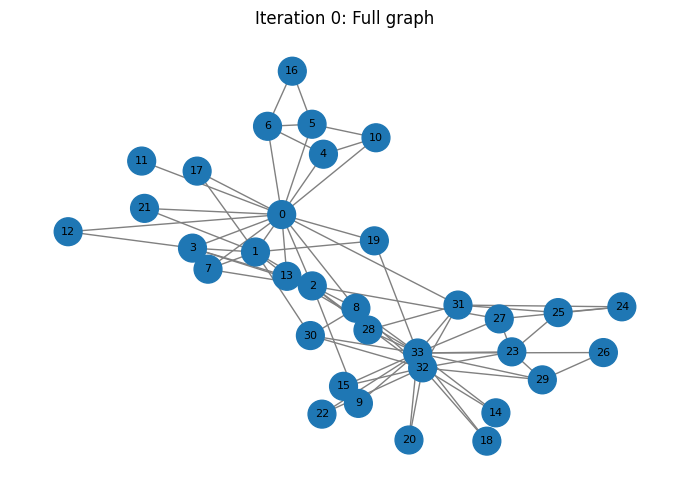

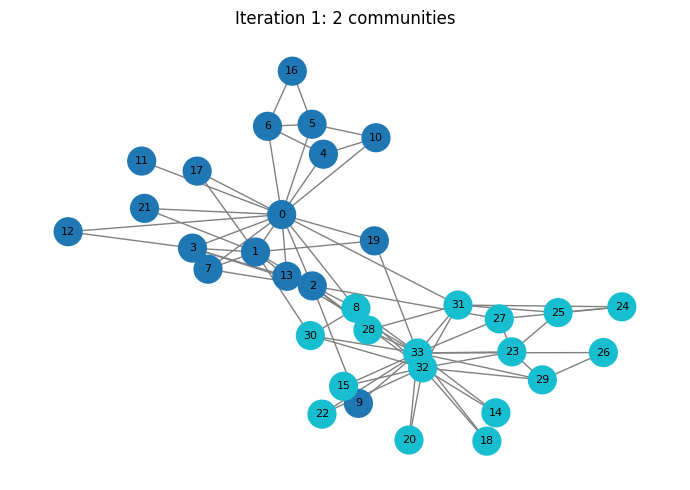

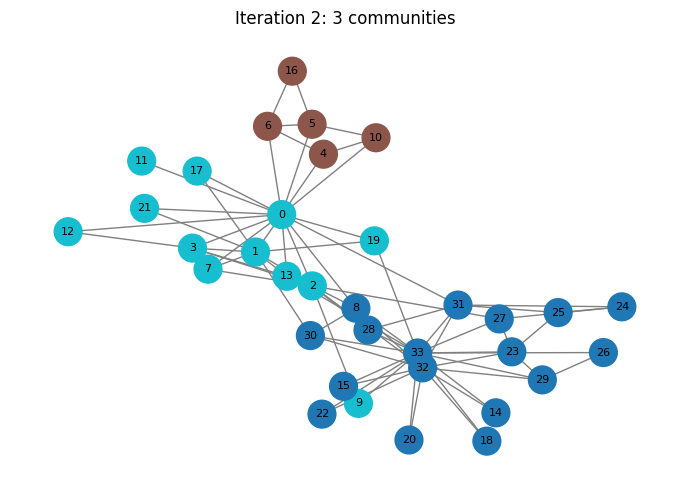

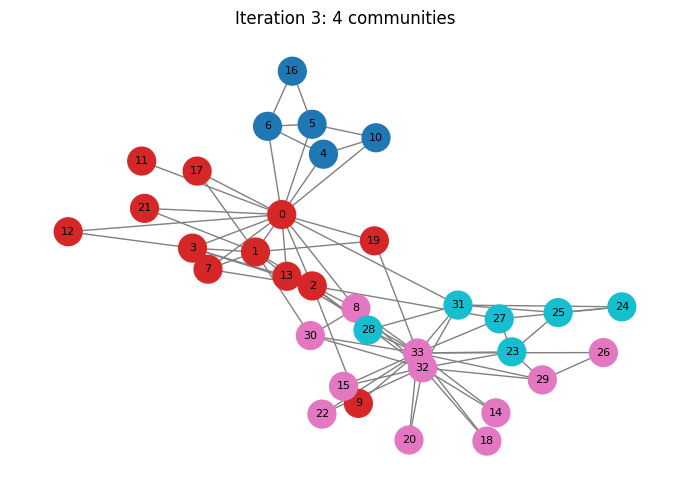

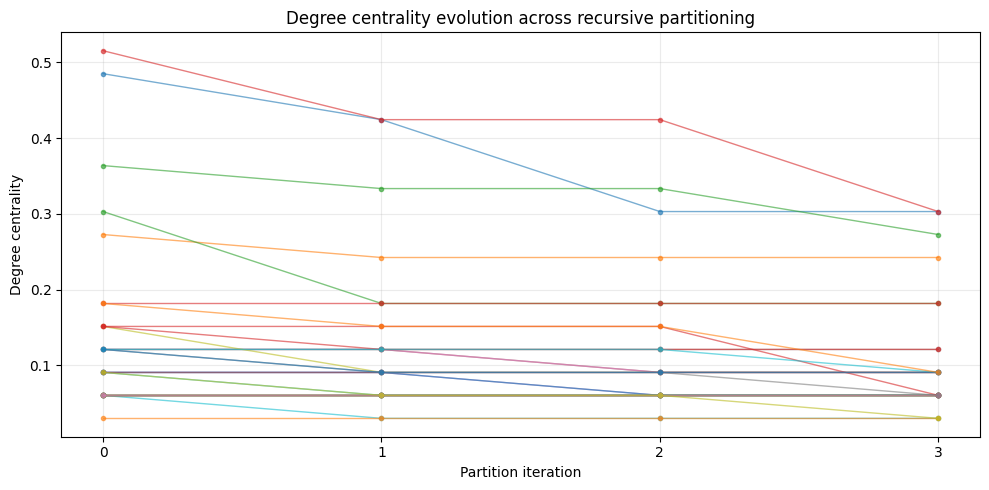

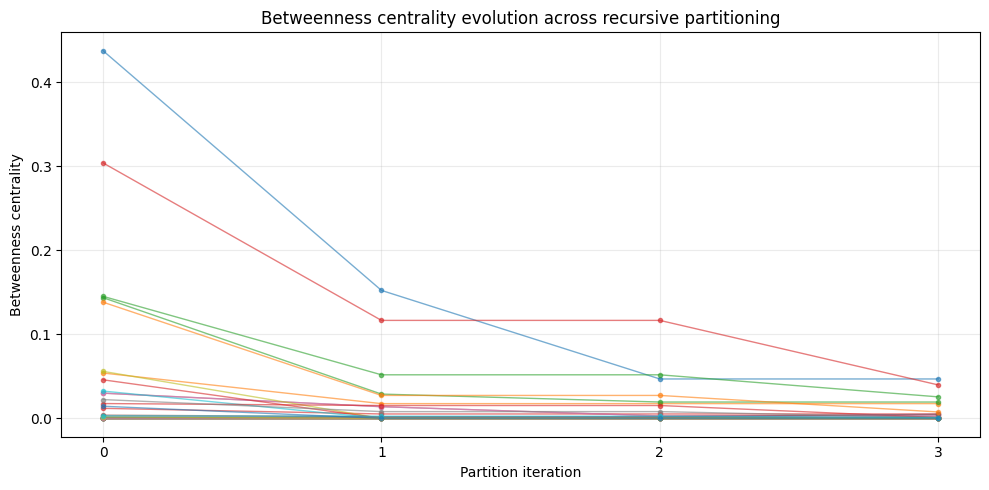

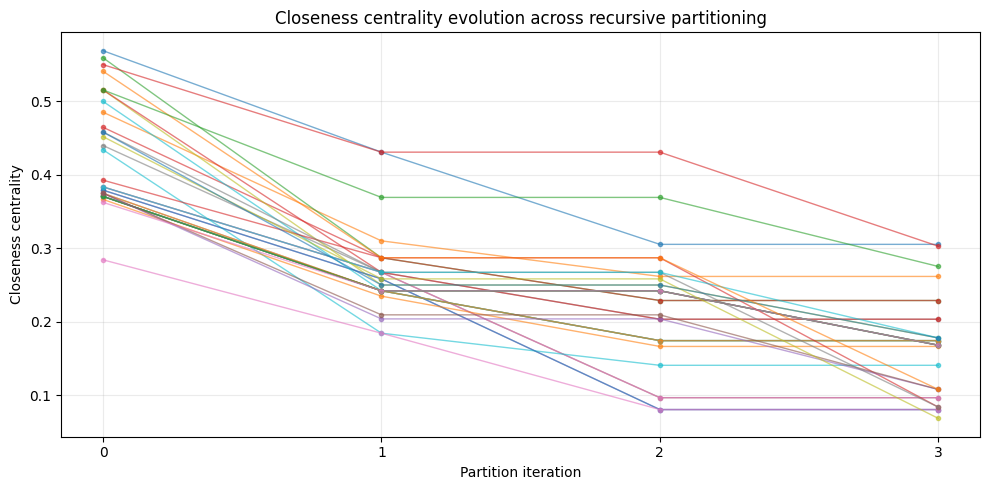

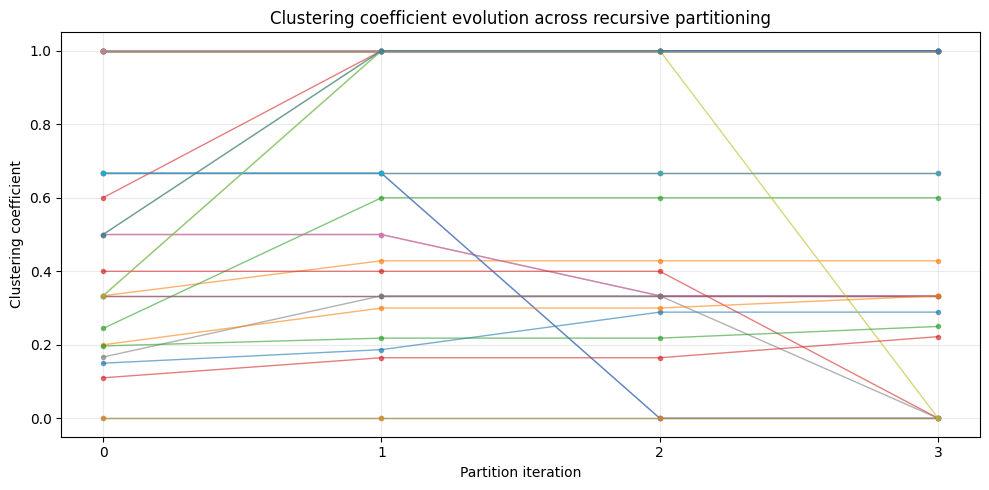

In [2]:
# Instantiate and run the refactored pipeline
partitioner = RecursiveSpectralPartitioner(nx.karate_club_graph())
partitioner.run()
partitioner.print_summary()

# Generate visual outputs
partitioner.plot_visualizations()
partitioner.plot_metrics()

## Discussion and Analysis of Results

### 1. Key Central Nodes
* **Node 0 (Mr. Hi)** and **Node 33 (John A.)** act as the primary hubs in Zachary's Karate Club. Throughout the recursive bisection splits, they consistently retain the highest degree, closeness, and betweenness centrality measures.
* Because the graph splits along the ideological faction boundaries surrounding these two figures, they remain the dominant internal leaders of their respective child communities.

### 2. Influence of Community Structure on Node Metrics
* **Betweenness Centrality Decay**: As community boundaries are established and inter-community edges are conceptually severed, the path length between nodes in opposing factions effectively becomes infinite. This causes a dramatic drop in betweenness centrality for bridging nodes (such as **Node 19** or **Node 31**) because they no longer act as gatekeepers for information flowing across the whole network.
* **Clustering Coefficient Splitting**: Locally dense groups (like the cliques surrounding **Node 0** and **Node 33**) maintain stable clustering coefficients. However, peripheral nodes that were poorly connected to begin with show sharp changes as their sparse connections are cut, isolating them further inside their local sub-graphs.

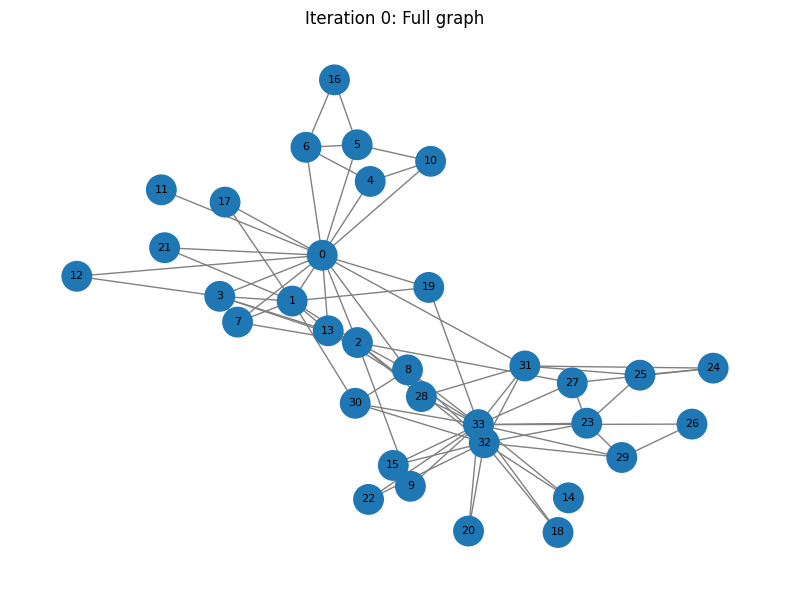

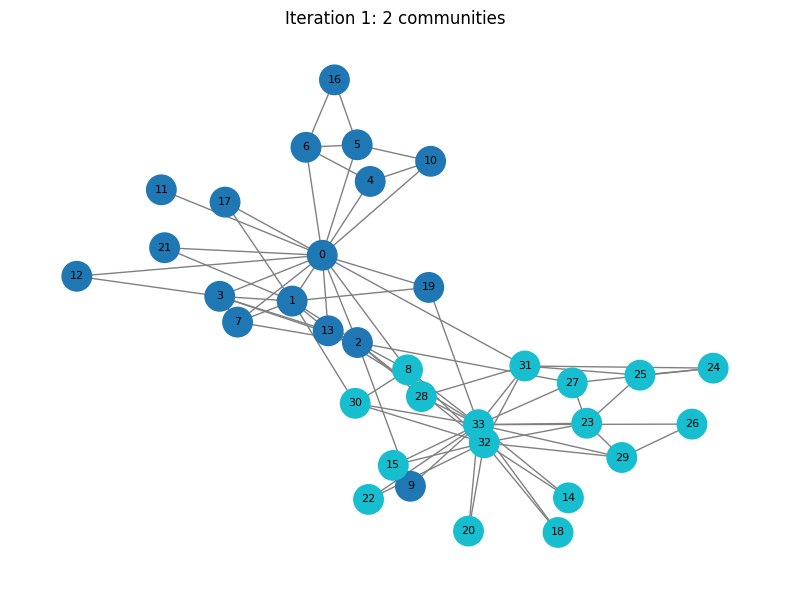

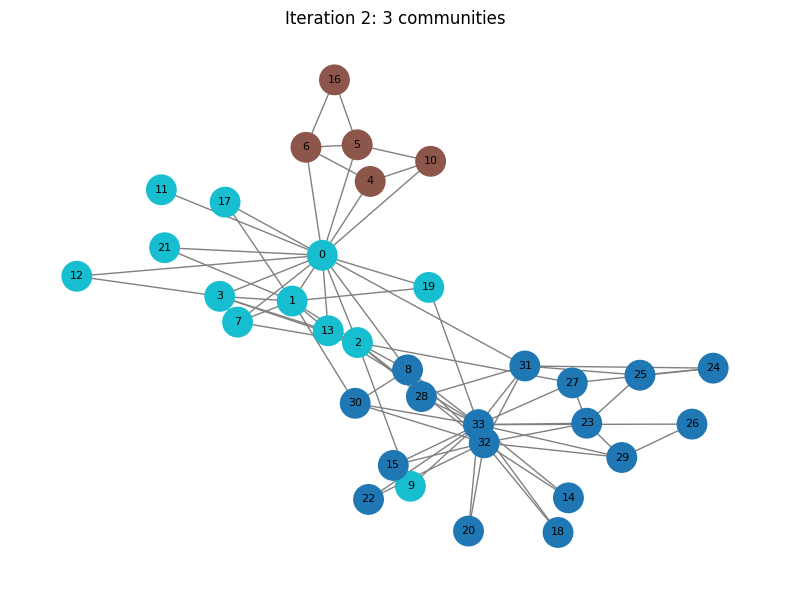

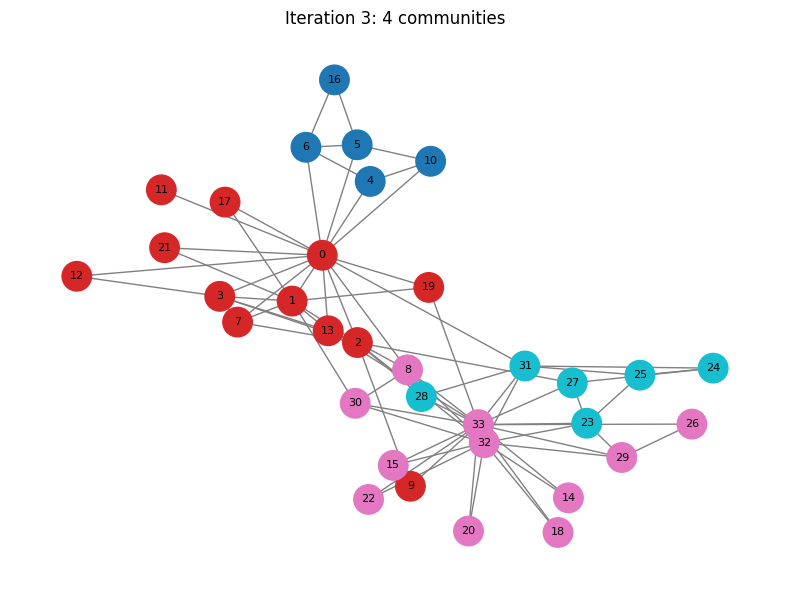

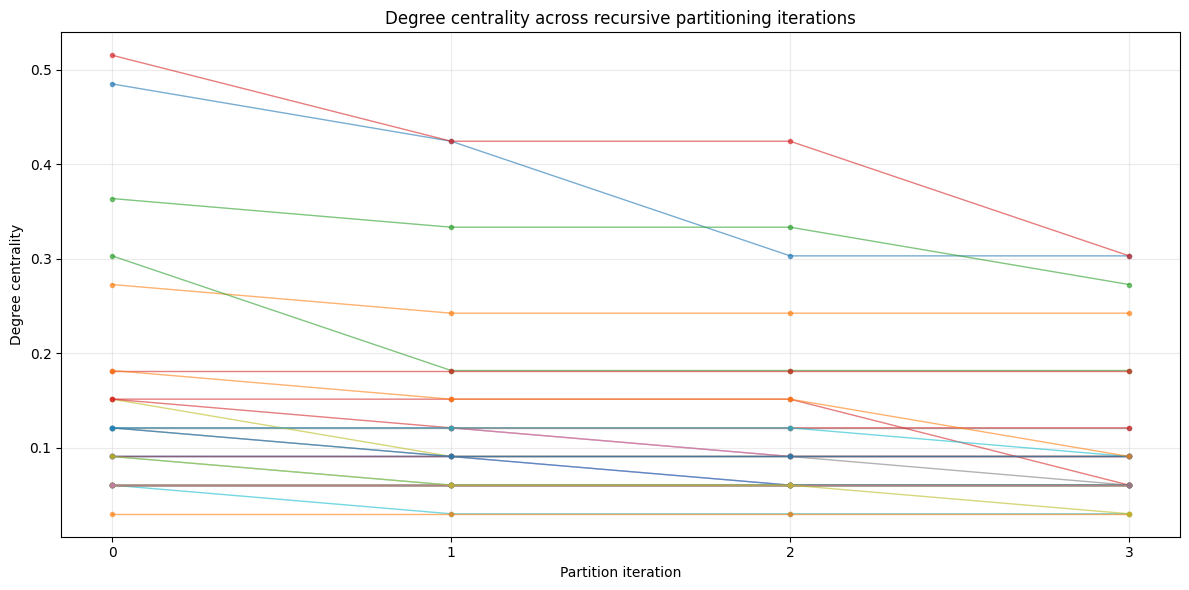

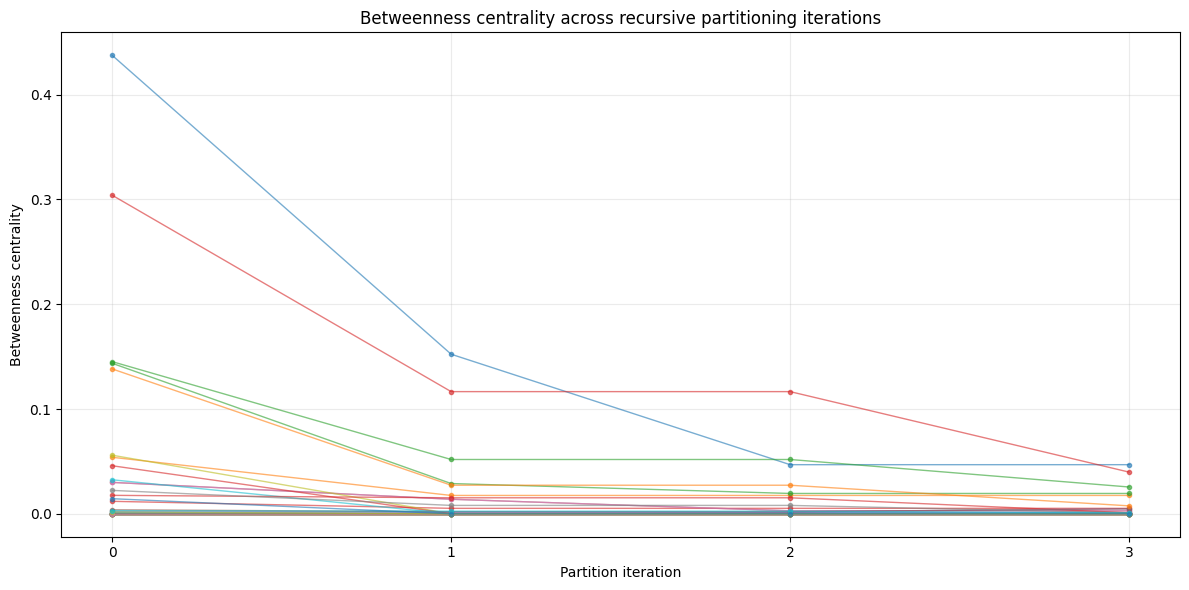

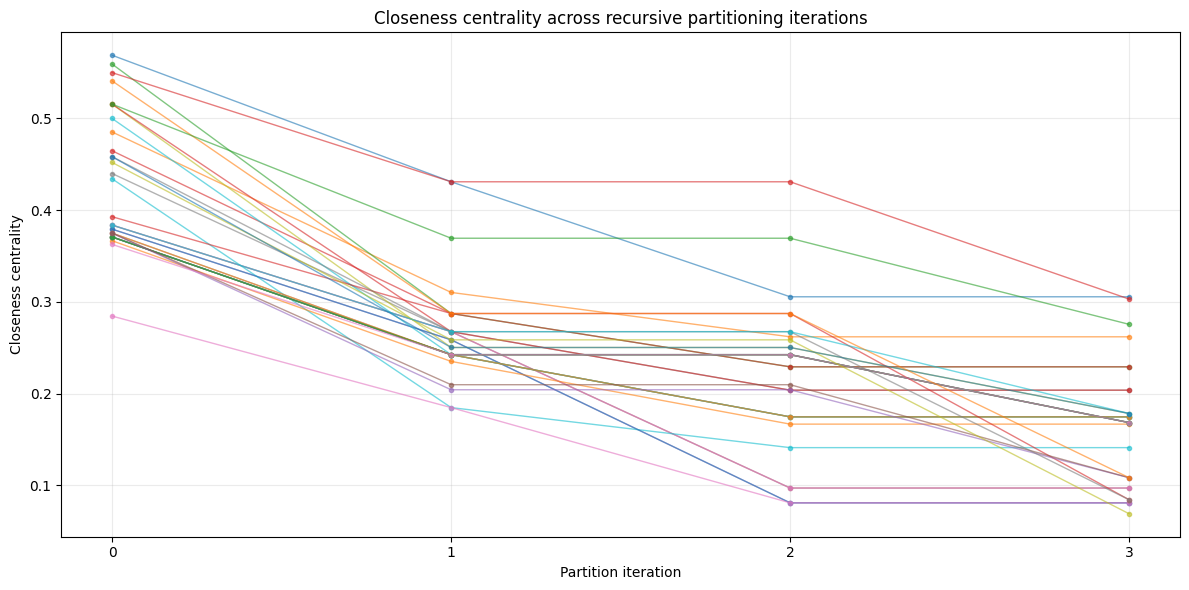

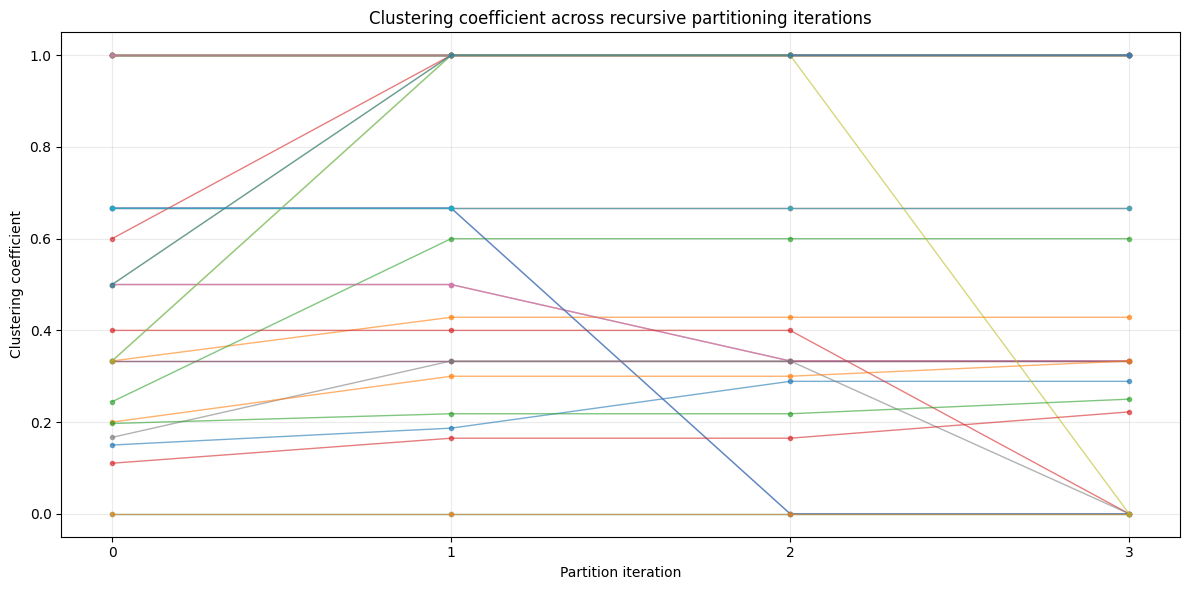

Karate Club graph: 34 nodes, 78 edges
Accepted splits: 3
Final communities: 4

Split log:
1. 34 -> 17 + 17; gain=0.371795; eigenvalue=4.977080
2. 17 -> 5 + 12; gain=0.030243; eigenvalue=1.173600
3. 17 -> 11 + 6; gain=0.016765; eigenvalue=0.808902

Final communities:
Community 1: [4, 5, 6, 10, 16]
Community 2: [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21]
Community 3: [8, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: [23, 24, 25, 27, 28, 31]

Top 5 nodes by metric in original graph:
Degree centrality: Node 33 (0.515), Node 0 (0.485), Node 32 (0.364), Node 2 (0.303), Node 1 (0.273)
Betweenness centrality: Node 0 (0.438), Node 33 (0.304), Node 32 (0.145), Node 2 (0.144), Node 31 (0.138)
Closeness centrality: Node 0 (0.569), Node 2 (0.559), Node 33 (0.550), Node 31 (0.541), Node 8 (0.516)
Clustering coefficient: Node 7 (1.000), Node 12 (1.000), Node 14 (1.000), Node 15 (1.000), Node 16 (1.000)


In [3]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# 1. Load Karate Club graph
G = nx.karate_club_graph()
nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
degrees = np.array([G.degree(i) for i in nodes])

# Global modularity matrix
B = A - np.outer(degrees, degrees) / (2 * m)

# Fixed layout
pos = nx.spring_layout(G, seed=42)

# 2. Compute node metrics
def compute_node_metrics(graph):
    return {
        "Degree centrality": nx.degree_centrality(graph),
        "Betweenness centrality": nx.betweenness_centrality(graph),
        "Closeness centrality": nx.closeness_centrality(graph),
        "Clustering coefficient": nx.clustering(graph)
    }

# 3. Spectral partitioning with sign refinement
def spectral_partition(C, tol=1e-10, max_passes=100):
    if len(C) < 2:
        return None

    idx = np.array(C, dtype=int)
    B_C = B[np.ix_(idx, idx)].copy()

    # Community-specific modularity matrix
    B_gamma = B_C - np.diag(B_C.sum(axis=1))

    eigenvalues, eigenvectors = np.linalg.eigh(B_gamma)
    j = np.argmax(eigenvalues)

    if eigenvalues[j] <= tol:
        return None

    signs = np.where(eigenvectors[:, j] >= 0, 1, -1)

    def gain(s):
        return float(s @ B_gamma @ s) / (4 * m)

    current_gain = gain(signs)

    # Greedily flip signs when modularity gain improves
    for _ in range(max_passes):
        best_gain = current_gain
        best_i = None

        for i in range(len(signs)):
            trial = signs.copy()
            trial[i] *= -1
            trial_gain = gain(trial)

            if trial_gain > best_gain + tol:
                best_gain = trial_gain
                best_i = i

        if best_i is None:
            break

        signs[best_i] *= -1
        current_gain = best_gain

    left = [C[i] for i in range(len(C)) if signs[i] == 1]
    right = [C[i] for i in range(len(C)) if signs[i] == -1]

    if not left or not right or current_gain <= tol:
        return None

    return left, right, current_gain, eigenvalues[j]

# 4. Recursive partitioning
communities = [nodes.copy()]
queue = [nodes.copy()]

snapshots = [
    ([c.copy() for c in communities], "Iteration 0: Full graph")
]
split_log = []

while queue:
    candidate = queue.pop(0)
    result = spectral_partition(candidate)

    if result is None:
        continue

    left, right, gain, leading_eigenvalue = result

    split_log.append(
        (candidate.copy(), left.copy(), right.copy(), gain, leading_eigenvalue)
    )

    communities.remove(candidate)
    communities.extend([left, right])
    queue.extend([left, right])

    snapshots.append((
        [c.copy() for c in communities],
        f"Iteration {len(split_log)}: {len(communities)} communities"
    ))

# 5. Calculate metrics after removing inter-community edges
def get_labels(partition):
    labels = {}
    for cid, community in enumerate(partition):
        for node in community:
            labels[node] = cid
    return labels

metric_history = []

for partition, _ in snapshots:
    labels = get_labels(partition)
    H = G.copy()

    H.remove_edges_from([
        (u, v) for u, v in G.edges()
        if labels[u] != labels[v]
    ])

    metric_history.append(compute_node_metrics(H))

# 6. Visualize graph after each split
for partition, title in snapshots:
    labels = get_labels(partition)

    plt.figure(figsize=(8, 6))

    nx.draw_networkx(
        G,
        pos,
        node_color=[labels[node] for node in nodes],
        cmap=plt.cm.tab10,
        node_size=450,
        font_size=8,
        edge_color="gray",
        with_labels=True
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# 7. Plot metric evolution across iterations
iterations = range(len(metric_history))

for metric in metric_history[0]:
    plt.figure(figsize=(12, 6))

    for node in nodes:
        values = [
            history[metric][node]
            for history in metric_history
        ]

        plt.plot(
            iterations,
            values,
            marker="o",
            markersize=3,
            linewidth=1,
            alpha=0.6
        )

    plt.xlabel("Partition iteration")
    plt.ylabel(metric)
    plt.title(f"{metric} across recursive partitioning iterations")
    plt.xticks(list(iterations))
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# 8. Print results
print(f"Karate Club graph: {n} nodes, {m} edges")
print(f"Accepted splits: {len(split_log)}")
print(f"Final communities: {len(communities)}")

print("\nSplit log:")
for i, (parent, left, right, gain, eigenvalue) in enumerate(
    split_log, start=1
):
    print(
        f"{i}. {len(parent)} -> {len(left)} + {len(right)}; "
        f"gain={gain:.6f}; eigenvalue={eigenvalue:.6f}"
    )

print("\nFinal communities:")
for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {sorted(community)}")

# 9. Top nodes by metrics in the original graph
original_metrics = compute_node_metrics(G)

print("\nTop 5 nodes by metric in original graph:")
for metric, values in original_metrics.items():
    top_nodes = sorted(
        values.items(),
        key=lambda item: item[1],
        reverse=True
    )[:5]

    print(
        metric + ": " +
        ", ".join(f"Node {node} ({value:.3f})"
                  for node, value in top_nodes)
    )

In [4]:
try:
    # Verify current pipeline works smoothly
    partitioner = RecursiveSpectralPartitioner(nx.karate_club_graph())
    partitioner.run()
    print("Pipeline ran successfully without any execution errors!")
except Exception as e:
    print(f"Pipeline failed with error: {e}")

Pipeline ran successfully without any execution errors!
